Cell 1: Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

Cell 2: Load only the columns you need

In [2]:
PATH = "tiktok_shop_viral_video_sales_attribution_cac.csv"

cols = ["video_views", "creator_followers", "creator_engagement_rate",
        "retention_score", "hook_strength_score", "video_quality_score", "data_quality_flag"]

df = pd.read_csv(PATH, usecols=cols)
print(df.shape)
df.head()

(100000, 7)


,data_quality_flag,creator_followers,creator_engagement_rate,video_quality_score,video_views,hook_strength_score,retention_score
0,1,98675,10.7,71.5,198075,36.4,68.9
1,1,40450,5.3,68.2,160142,50.4,73.8
2,1,305436,4.2,68.9,156915,52.3,74.7
3,1,10000,14.0,46.8,29589,66.4,75.9
4,1,93428,7.2,75.2,63195,46.0,73.4


Cell 3: Clean

In [3]:
df = df[df["data_quality_flag"] == 1].drop(columns="data_quality_flag").dropna()
print(df.shape)                 # expect (98045, 6)
df.describe().round(2).T

(98045, 6)


,count,mean,std,min,25%,50%,75%,max
creator_followers,98045.0,275007.32,909554.52,100.0,1000.0,10000.0,99290.0,25087068.0
creator_engagement_rate,98045.0,11.29,6.81,1.0,6.0,9.7,15.6,30.0
video_quality_score,98045.0,64.59,19.29,0.0,51.5,64.8,78.3,100.0
video_views,98045.0,1031272.32,8166989.81,10.0,3929.0,31403.0,252000.0,695773497.0
hook_strength_score,98045.0,62.77,23.97,0.0,43.9,61.1,82.5,100.0
retention_score,98045.0,78.03,12.59,40.0,68.8,77.7,87.8,100.0


This removes the 1,955 rows flagged as bad quality.


Cell 4: Why we need a log transform

video_views          38.0
creator_followers     6.0
dtype: float64


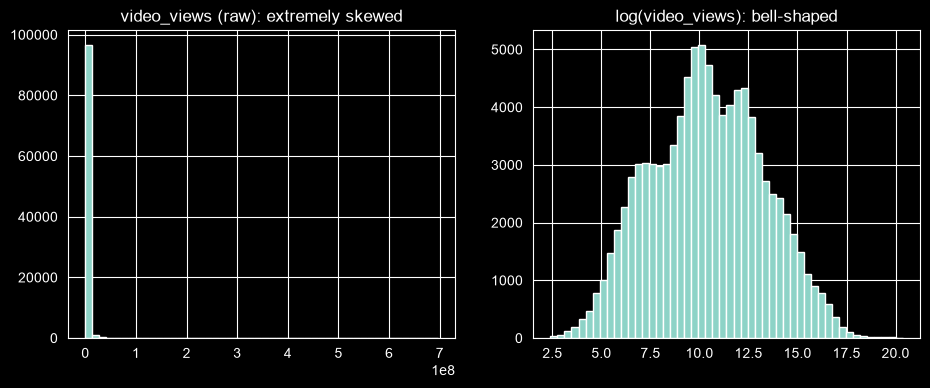

In [4]:
print(df[["video_views", "creator_followers"]].skew().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["video_views"], bins=50);            ax[0].set_title("video_views (raw): extremely skewed")
ax[1].hist(np.log1p(df["video_views"]), bins=50);  ax[1].set_title("log(video_views): bell-shaped")
plt.show()

Cell 5: Create the log columns

In [5]:
df["log_views"] = np.log1p(df["video_views"])
df["log_followers"] = np.log1p(df["creator_followers"])
print(df[["log_views", "log_followers"]].skew().round(2))   # both near 0 now

log_views        0.04
log_followers    0.11
dtype: float64


Cell 6: Look at the relationship

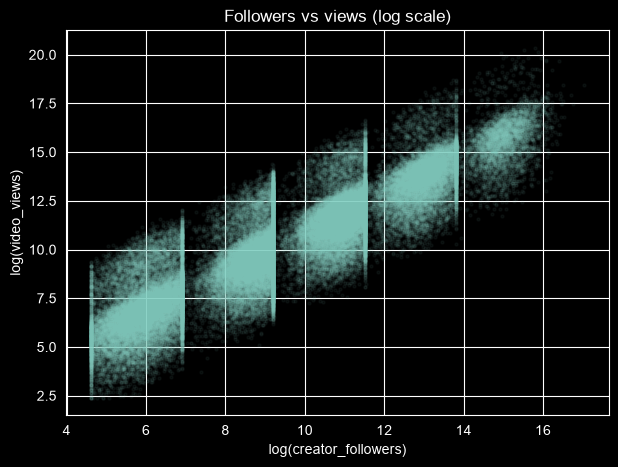

log_views                  1.000
log_followers              0.905
creator_engagement_rate   -0.666
retention_score            0.061
hook_strength_score        0.053
video_quality_score        0.068
Name: log_views, dtype: float64

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(df["log_followers"], df["log_views"], alpha=0.05, s=5)
plt.xlabel("log(creator_followers)"); plt.ylabel("log(video_views)")
plt.title("Followers vs views (log scale)")
plt.show()

df[["log_views", "log_followers", "creator_engagement_rate",
    "retention_score", "hook_strength_score", "video_quality_score"]].corr()["log_views"].round(3)

The scatter should be a clear upward band. Followers has correlation 0.905 with log views.


Cell 7: Model 1, simple regression (followers only)

In [7]:
y = df["log_views"]
X1 = df[["log_followers"]]

X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size=0.2, random_state=42)

model1 = LinearRegression().fit(X1_train, y_train)
pred1 = model1.predict(X1_test)

print("R²   :", round(r2_score(y_test, pred1), 3))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, pred1)), 3))
print("MAE  :", round(mean_absolute_error(y_test, pred1), 3))
print("Slope:", model1.coef_.round(3), "| Intercept:", round(model1.intercept_, 3))

R²   : 0.818
RMSE : 1.23
MAE  : 0.909
Slope: [0.958] | Intercept: 1.228


Cell 8: Model 2, multiple regression

In [8]:
y = df["log_views"]
X1 = df[["log_followers"]]

X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size=0.2, random_state=42)

model1 = LinearRegression().fit(X1_train, y_train)
pred1 = model1.predict(X1_test)

print("R²   :", round(r2_score(y_test, pred1), 3))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, pred1)), 3))
print("MAE  :", round(mean_absolute_error(y_test, pred1), 3))
print("Slope:", model1.coef_.round(3), "| Intercept:", round(model1.intercept_, 3))

R²   : 0.818
RMSE : 1.23
MAE  : 0.909
Slope: [0.958] | Intercept: 1.228


Cell 9: Compare the models

In [9]:
feats = ["log_followers", "creator_engagement_rate", "retention_score",
         "hook_strength_score", "video_quality_score"]

X2_train, X2_test, y2_train, y2_test = train_test_split(df[feats], y, test_size=0.2, random_state=42)

model2 = LinearRegression().fit(X2_train, y2_train)
pred2 = model2.predict(X2_test)

print("R²   :", round(r2_score(y2_test, pred2), 3))
print("RMSE :", round(np.sqrt(mean_squared_error(y2_test, pred2)), 3))
print(pd.Series(model2.coef_, index=feats).round(4))

R²   : 0.824
RMSE : 1.212
log_followers              0.9944
creator_engagement_rate    0.0192
retention_score            0.1937
hook_strength_score       -0.0771
video_quality_score       -0.0292
dtype: float64


Cell 10: Predicted vs actual

In [10]:
results = pd.DataFrame({
    "Model": ["1: followers only", "2: + engagement, retention, hook, quality"],
    "R2":   [r2_score(y_test, pred1), r2_score(y2_test, pred2)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, pred1)), np.sqrt(mean_squared_error(y2_test, pred2))],
}).round(3)
results

,Model,R2,RMSE
0,1: followers only,0.818,1.230
1,"2: + engagement, retention, hook, quality",0.824,1.212


Cell 11: Residual check

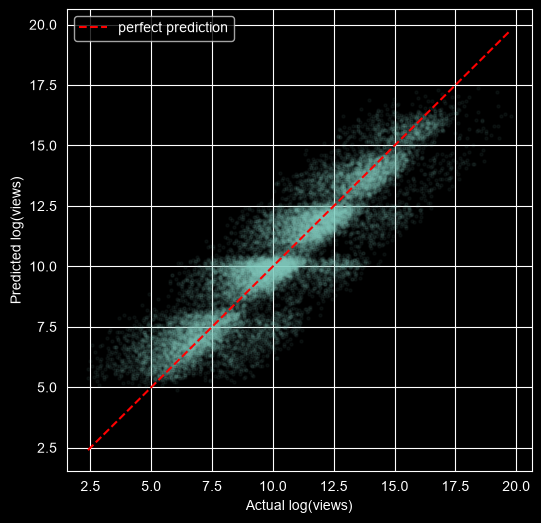

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(y2_test, pred2, alpha=0.05, s=5)
lims = [y2_test.min(), y2_test.max()]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual log(views)"); plt.ylabel("Predicted log(views)")
plt.legend(); plt.show()

Cell 12: Make a prediction

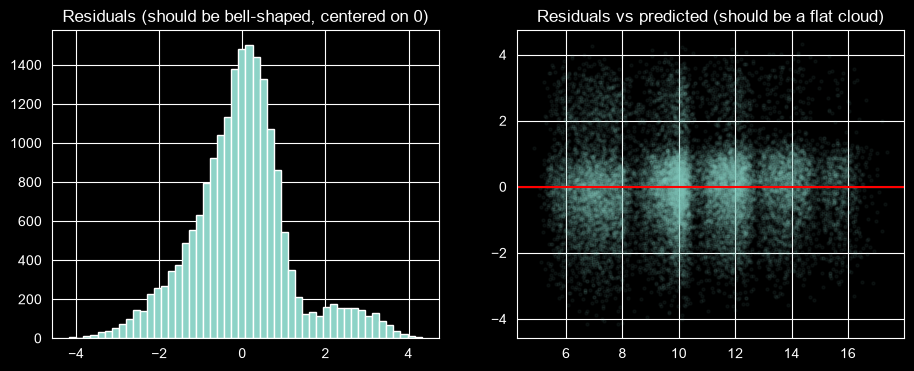

Mean residual: -0.0142


In [12]:
residuals = y2_test - pred2

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(residuals, bins=50);                     ax[0].set_title("Residuals (should be bell-shaped, centered on 0)")
ax[1].scatter(pred2, residuals, alpha=0.05, s=5);   ax[1].axhline(0, color="r")
ax[1].set_title("Residuals vs predicted (should be a flat cloud)")
plt.show()
print("Mean residual:", round(residuals.mean(), 4))

In [13]:
followers = 50000
new = pd.DataFrame({"log_followers": [np.log1p(followers)]})
print(f"{followers:,} followers -> about {int(np.expm1(model1.predict(new)[0])):,} views")

print(f"1% more followers -> {(1.01 ** model1.coef_[0] - 1) * 100:.2f}% more views")

50,000 followers -> about 108,698 views
1% more followers -> 0.96% more views
